# 5. Tujuan 1: kondisi dan tren kualitas udara

Peringkat stasiun, perbandingan dengan baku mutu PP 22/2021 dan pedoman WHO 2021, komposisi kategori ISPU, sebaran per pulau, tren bulanan, uji Seasonal Mann-Kendall dan Sen's slope, serta perbandingan musim asap antartahun dengan uji Mann-Whitney.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymannkendall as mk
from scipy.stats import mannwhitneyu

MART = "../data/mart/"
OUT = "../hasil/"
GAMBAR = OUT + "gambar/"
WARNA_ISPU = {"Baik": "#2e7d32", "Sedang": "#1565c0", "Tidak Sehat": "#f9a825",
              "Sangat Tidak Sehat": "#c62828", "Berbahaya": "#212121"}
WARNA_PULAU = {"Jawa": "#1565c0", "Sumatera": "#2e7d32", "Kalimantan": "#c62828",
               "Sulawesi": "#f9a825", "Papua": "#6a1b9a"}

In [3]:
dim = pd.read_csv(MART + "dim_lokasi.csv")
d = pd.read_csv(MART + "fakta_udara_harian.csv", parse_dates=["tanggal"])
d = d.merge(dim[["stasiun", "nama_stasiun", "pulau", "kategori_lokasi", "wilayah_gambut", "baseline_pm25"]], on="stasiun")
v = d[d["hari_valid"]]
jam = pd.read_csv(MART + "fakta_udara_per_jam.csv", usecols=["stasiun", "pm25", "pm10", "tahun"])

rank = v.groupby(["stasiun", "pulau", "kategori_lokasi"]).agg(
    hari_valid=("pm25", "size"),
    pm25_rata2=("pm25", "mean"),
    pm25_median=("pm25", "median"),
    pm25_p95=("pm25", lambda s: s.quantile(0.95)),
    pm25_maks=("pm25", "max"),
    pm10_rata2=("pm10", "mean"),
    pct_hari_lewat_bm_pm25=("lewat_bm_pm25", "mean"),
    pct_hari_lewat_bm_pm10=("lewat_bm_pm10", "mean"),
    pct_hari_lewat_who_pm25=("lewat_who_pm25", "mean"),
    hari_tidak_sehat_ke_atas=("ispu", lambda s: int((s > 100).sum())),
    hari_berbahaya=("ispu", lambda s: int((s > 300).sum())),
).reset_index()
for c in [c for c in rank.columns if c.startswith("pct_")]:
    rank[c] = (rank[c] * 100).round(1)
rank["rasio_rata2_vs_bm_tahunan_pm25"] = (rank["pm25_rata2"] / 15).round(1)
rank["rasio_rata2_vs_who_tahunan_pm25"] = (rank["pm25_rata2"] / 5).round(1)
rank = rank.sort_values("pm25_rata2", ascending=False).round(1)
rank.insert(0, "peringkat", range(1, len(rank) + 1))

In [4]:
mer = jam[jam["stasiun"] == "MER-01"]
mer_baris = {"stasiun": "MER-01", "catatan": "data terbatas, dari jam valid saja",
             "pm25_rata2_per_jam": round(mer["pm25"].mean(), 1), "pm10_rata2_per_jam": round(mer["pm10"].mean(), 1),
             "jam_terisi": int(mer["pm25"].notna().sum())}

tahunan = v.groupby(["stasiun", "tahun"]).agg(pm25=("pm25", "mean"), pm10=("pm10", "mean"), hari=("pm25", "size")).reset_index()
tahunan["lewat_bm_tahunan_pm25"] = tahunan["pm25"] > 15
tahunan["lewat_bm_tahunan_pm10"] = tahunan["pm10"] > 40
tahunan["catatan"] = np.where(tahunan["tahun"] == 2026, "Jan–14 Okt", "setahun penuh")

In [5]:
jan_okt = v[v["tanggal"].dt.strftime("%m-%d") <= "10-14"]
banding = jan_okt.pivot_table(index="stasiun", columns="tahun", values="pm25", aggfunc="mean").round(1)
banding["perubahan_2024_2026_pct"] = ((banding[2026] / banding[2024] - 1) * 100).round(1)

kemarau = v[v["bulan"].between(7, 10)].pivot_table(index="stasiun", columns="tahun", values="pm25", aggfunc="mean").round(1)
kemarau.columns = [f"jul_okt_{c}" for c in kemarau.columns]
hujan = v[v["bulan"].between(1, 4)].pivot_table(index="stasiun", columns="tahun", values="pm25", aggfunc="mean").round(1)
hujan.columns = [f"jan_apr_{c}" for c in hujan.columns]

In [6]:
bulanan = v.groupby(["stasiun", pd.Grouper(key="tanggal", freq="MS")])["pm25"].agg(["mean", "size"]).reset_index()
bulanan = bulanan[bulanan["size"] >= 15]
tren = []
for s, g in bulanan.groupby("stasiun"):
    seri = g.set_index("tanggal")["mean"].asfreq("MS")
    r = mk.seasonal_test(seri.values, period=12)
    tren.append({
        "stasiun": s, "bulan_dipakai": int(seri.notna().sum()),
        "tau": round(r.Tau, 3), "p_value": round(r.p, 4),
        "sen_slope_per_tahun": round(r.slope, 2),
        "kesimpulan": "Memburuk" if (r.p < 0.05 and r.slope > 0) else "Membaik" if (r.p < 0.05 and r.slope < 0) else "Stabil / tidak signifikan",
    })
tren = pd.DataFrame(tren).merge(banding.reset_index()[["stasiun", 2024, 2025, 2026, "perubahan_2024_2026_pct"]], on="stasiun")
tren = tren.merge(kemarau.reset_index(), on="stasiun").merge(hujan.reset_index(), on="stasiun")
uji = []
for st, g in v.groupby("stasiun"):
    a = g.loc[(g["tahun"] == 2024) & g["bulan"].between(7, 10), "pm25"]
    b = g.loc[(g["tahun"] == 2026) & g["bulan"].between(7, 10), "pm25"]
    if len(a) > 20 and len(b) > 20:
        p_mw = mannwhitneyu(b, a, alternative="two-sided").pvalue
        uji.append({"stasiun": st, "median_jul_okt_2024": round(a.median(), 1), "median_jul_okt_2026": round(b.median(), 1),
                    "p_mann_whitney": round(p_mw, 4),
                    "musim_asap_2026_vs_2024": "Lebih buruk" if (p_mw < 0.05 and b.median() > a.median())
                    else "Lebih baik" if (p_mw < 0.05 and b.median() < a.median()) else "Tidak berbeda"})
tren = tren.merge(pd.DataFrame(uji), on="stasiun", how="left")
tren = tren.sort_values("sen_slope_per_tahun", ascending=False)

In [7]:
pulau = v.groupby("pulau").agg(
    stasiun=("stasiun", "nunique"), pm25_rata2=("pm25", "mean"), pm25_median=("pm25", "median"),
    pm25_p95=("pm25", lambda s: s.quantile(0.95)),
    pct_lewat_bm=("lewat_bm_pm25", "mean"), pct_tidak_sehat=("ispu", lambda s: (s > 100).mean()),
).reset_index()
pulau[["pct_lewat_bm", "pct_tidak_sehat"]] *= 100
pulau = pulau.sort_values("pm25_rata2", ascending=False).round(1)

In [8]:
kat = v.groupby("kategori_lokasi").agg(stasiun=("stasiun", "nunique"), pm25_rata2=("pm25", "mean"),
                                        pm25_median=("pm25", "median"), pct_lewat_bm=("lewat_bm_pm25", "mean")).reset_index()
kat["pct_lewat_bm"] *= 100
kat = kat.sort_values("pm25_rata2", ascending=False).round(1)

ispu_pct = pd.crosstab(v["stasiun"], v["kategori_ispu"], normalize="index").mul(100).round(1)
ispu_pct = ispu_pct[[k for k in WARNA_ISPU if k in ispu_pct.columns]]

gas = v.groupby("stasiun")[["lewat_bm_no2", "lewat_bm_co", "lewat_bm_so2", "lewat_bm_o3"]].sum()
gas = gas[gas.sum(axis=1) > 0]
gas_rata = v.groupby("stasiun")[["so2", "no2", "co", "o3"]].mean().round(1)

In [9]:
with pd.ExcelWriter(OUT + "04_T1_kondisi_tren.xlsx") as w:
    rank.to_excel(w, sheet_name="ranking_stasiun", index=False)
    pd.DataFrame([mer_baris]).to_excel(w, sheet_name="catatan_MER01", index=False)
    pulau.to_excel(w, sheet_name="per_pulau", index=False)
    kat.to_excel(w, sheet_name="per_kategori_lokasi", index=False)
    ispu_pct.to_excel(w, sheet_name="pct_hari_kategori_ispu")
    tahunan.round(1).to_excel(w, sheet_name="rata2_tahunan", index=False)
    tren.to_excel(w, sheet_name="tren_mann_kendall", index=False)
    gas.to_excel(w, sheet_name="gas_hari_lewat_bm")
    gas_rata.to_excel(w, sheet_name="gas_rata2")

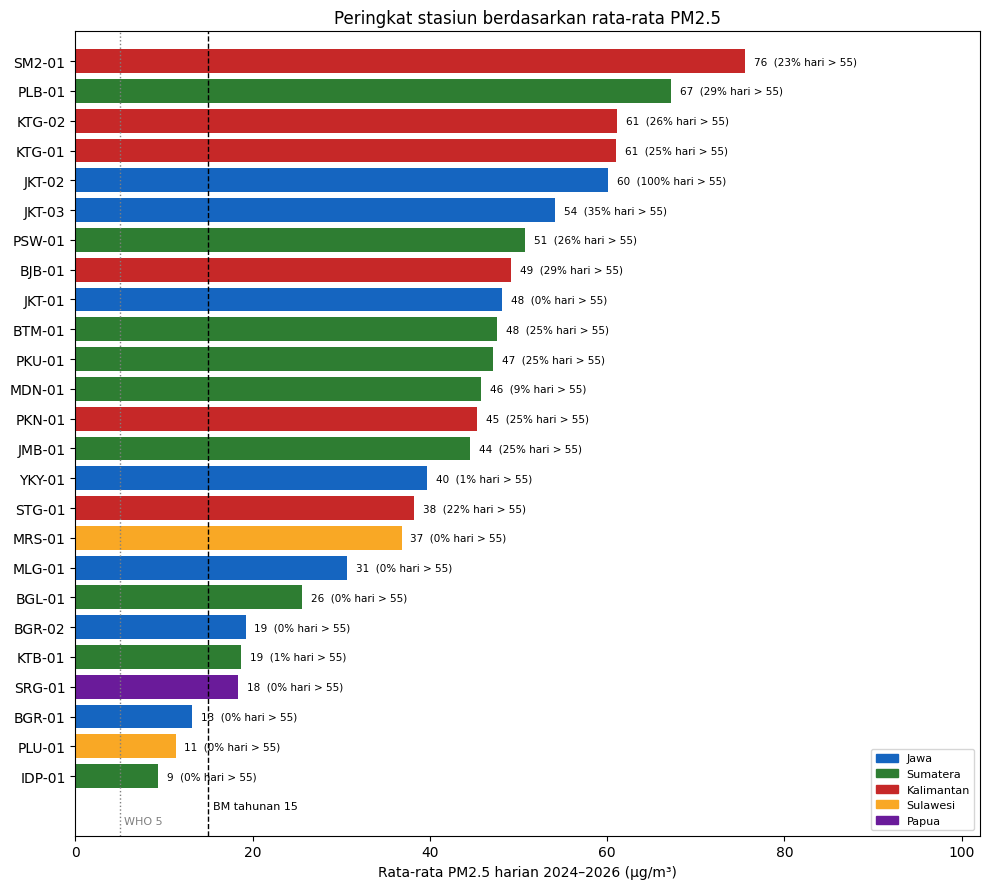

In [10]:
r = rank.sort_values("pm25_rata2")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(r["stasiun"], r["pm25_rata2"], color=[WARNA_PULAU[p] for p in r["pulau"]])
ax.axvline(15, color="black", ls="--", lw=1)
ax.axvline(5, color="grey", ls=":", lw=1)
ax.text(15.5, -1.1, "BM tahunan 15", fontsize=8)
ax.text(5.5, -1.6, "WHO 5", fontsize=8, color="grey")
for y, (val, pct) in enumerate(zip(r["pm25_rata2"], r["pct_hari_lewat_bm_pm25"])):
    ax.text(val + 1, y, f"{val:.0f}  ({pct:.0f}% hari > 55)", va="center", fontsize=7.5)
ax.set_xlabel("Rata-rata PM2.5 harian 2024–2026 (µg/m³)")
ax.set_title("Peringkat stasiun berdasarkan rata-rata PM2.5")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in WARNA_PULAU.values()], labels=WARNA_PULAU.keys(),
          loc="lower right", fontsize=8)
ax.set_xlim(0, r["pm25_rata2"].max() * 1.35)
ax.set_ylim(-2, len(r))
plt.tight_layout()
plt.savefig(GAMBAR + "04_T1_ranking_pm25.png", dpi=150)
plt.show()

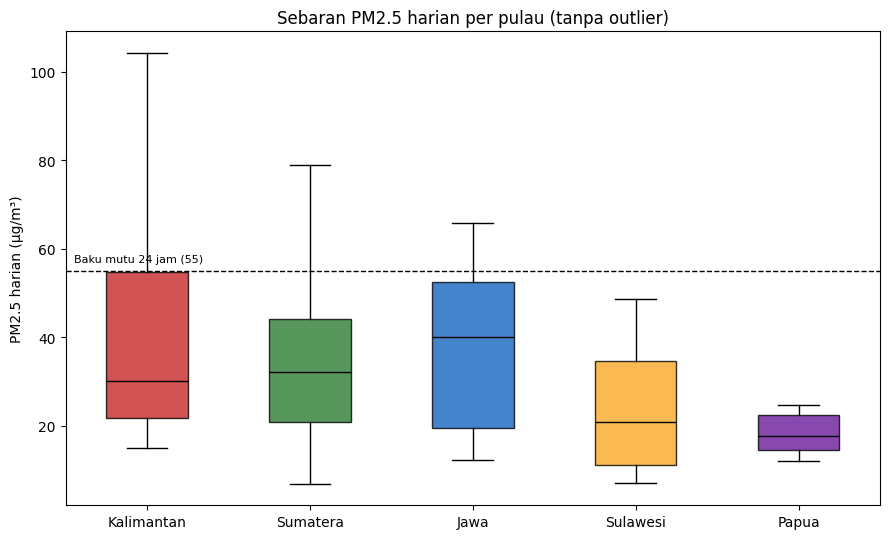

In [11]:
urut = pulau["pulau"].tolist()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.boxplot([v.loc[v["pulau"] == p, "pm25"] for p in urut], labels=urut, showfliers=False, patch_artist=True,
           boxprops=dict(alpha=0.8), medianprops=dict(color="black"))
for patch, p in zip(ax.artists if ax.artists else ax.patches, urut):
    patch.set_facecolor(WARNA_PULAU[p])
ax.axhline(55, color="black", ls="--", lw=1)
ax.text(0.55, 57, "Baku mutu 24 jam (55)", fontsize=8)
ax.set_ylabel("PM2.5 harian (µg/m³)")
ax.set_title("Sebaran PM2.5 harian per pulau (tanpa outlier)")
plt.tight_layout()
plt.savefig(GAMBAR + "04_T1_boxplot_pulau.png", dpi=150)
plt.show()

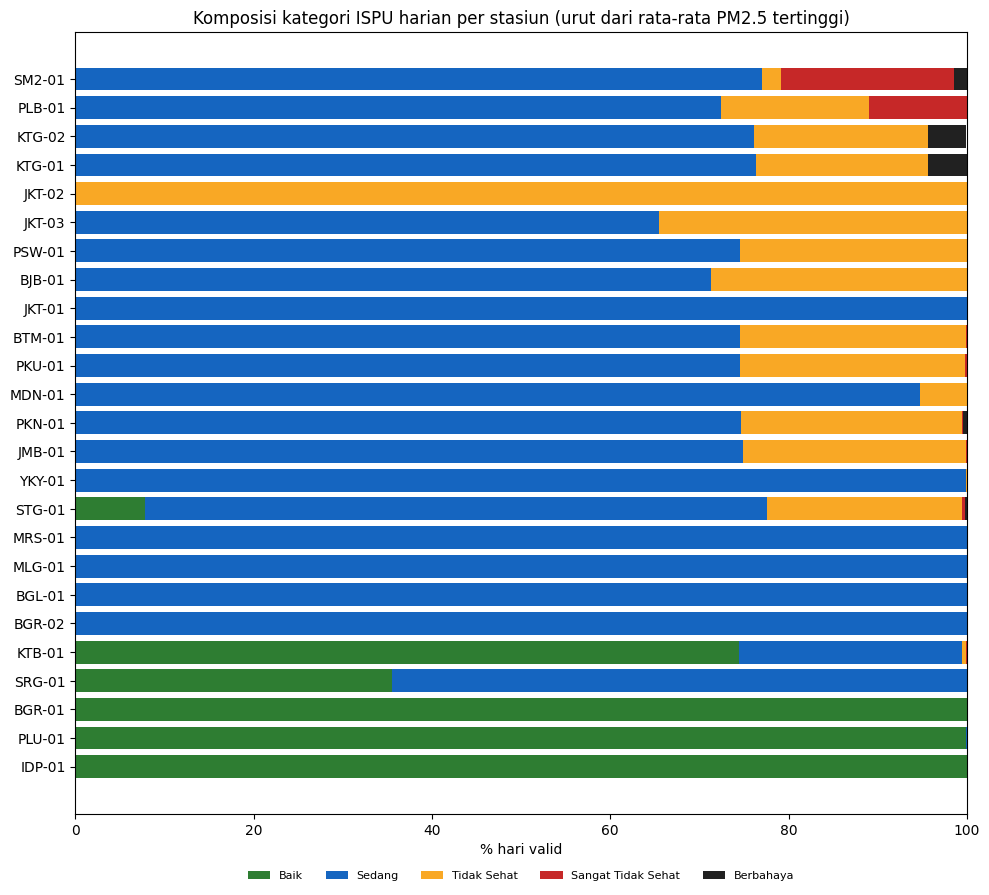

In [12]:
ip = ispu_pct.loc[rank["stasiun"][::-1]]
fig, ax = plt.subplots(figsize=(10, 9))
kiri = np.zeros(len(ip))
for k in ip.columns:
    ax.barh(ip.index, ip[k], left=kiri, color=WARNA_ISPU[k], label=k)
    kiri += ip[k].values
ax.set_xlim(0, 100)
ax.set_xlabel("% hari valid")
ax.set_title("Komposisi kategori ISPU harian per stasiun (urut dari rata-rata PM2.5 tertinggi)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=5, frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR + "04_T1_komposisi_ispu.png", dpi=150)
plt.show()

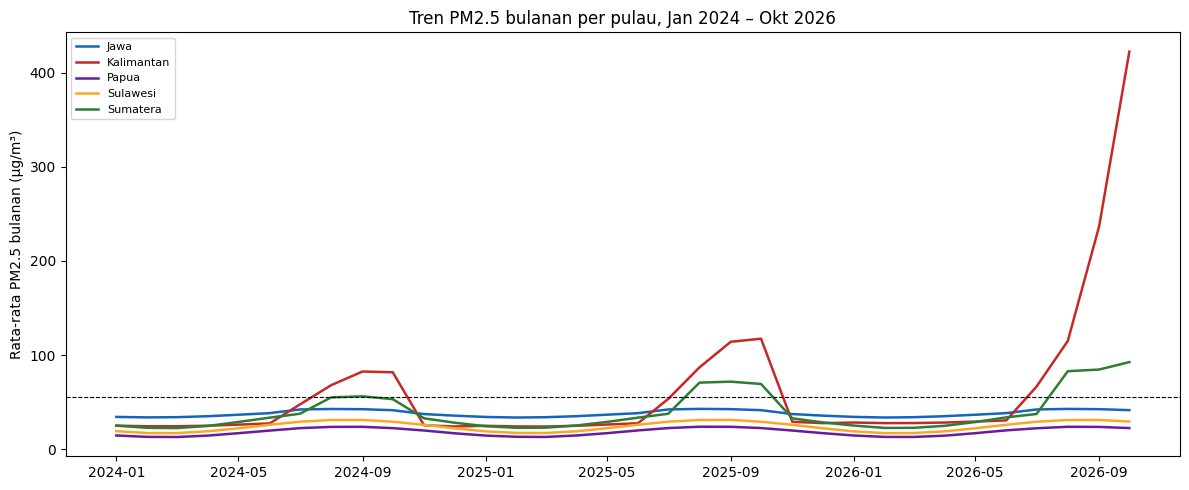

In [13]:
bul = v.groupby(["pulau", pd.Grouper(key="tanggal", freq="MS")])["pm25"].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
for p, g in bul.groupby("pulau"):
    ax.plot(g["tanggal"], g["pm25"], label=p, color=WARNA_PULAU[p], lw=1.8)
ax.axhline(55, color="black", ls="--", lw=0.8)
ax.set_ylabel("Rata-rata PM2.5 bulanan (µg/m³)")
ax.set_title("Tren PM2.5 bulanan per pulau, Jan 2024 – Okt 2026")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR + "04_T1_tren_bulanan_pulau.png", dpi=150)
plt.show()

In [14]:
pd.set_option("display.width", 250)
print(rank.to_string())
print(mer_baris)
print(pulau.to_string())
print(kat.to_string())
print(tren.to_string())
print(gas.to_string())
print(gas_rata.to_string())
print(tahunan.groupby("tahun")[["lewat_bm_tahunan_pm25", "lewat_bm_tahunan_pm10"]].sum())

    peringkat stasiun       pulau kategori_lokasi  hari_valid  pm25_rata2  pm25_median  pm25_p95  pm25_maks  pm10_rata2  pct_hari_lewat_bm_pm25  pct_hari_lewat_bm_pm10  pct_hari_lewat_who_pm25  hari_tidak_sehat_ke_atas  hari_berbahaya  rasio_rata2_vs_bm_tahunan_pm25  rasio_rata2_vs_who_tahunan_pm25
21          1  SM2-01  Kalimantan        Industri         865        75.6         43.8     211.8      310.8       126.8                    23.1                    53.5                    100.0                       199              12                             5.0                             15.1
18          2  PLB-01    Sumatera          Gambut         890        67.2         43.3     175.4      238.7        88.9                    29.1                    34.9                    100.0                       246               0                             4.5                             13.4
12          3  KTG-02  Kalimantan          Gambut        1018        61.1         22.6     126.1    

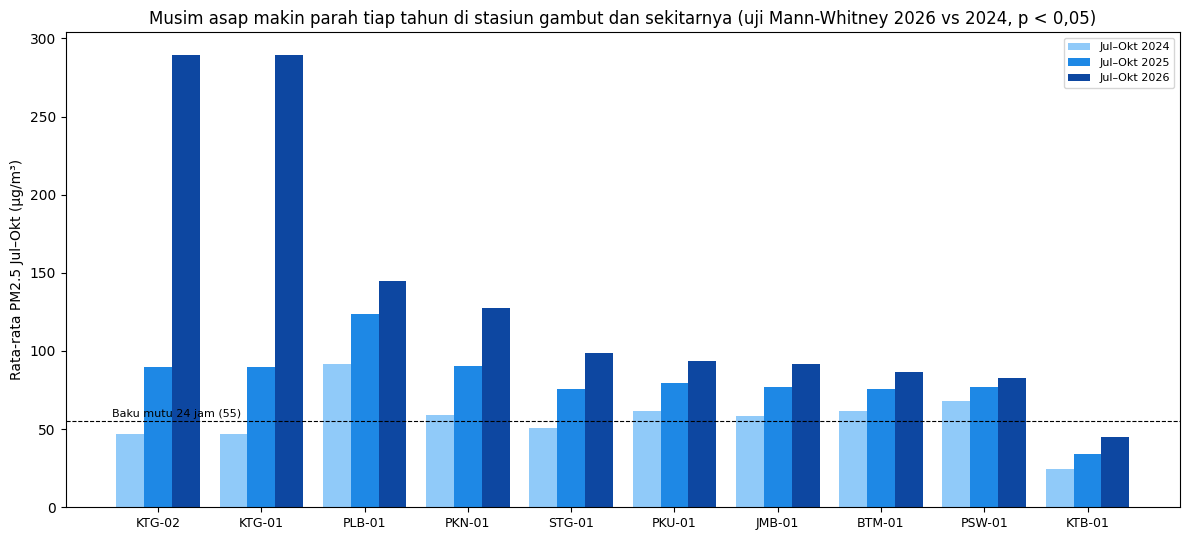

In [15]:
pilih = tren[tren["musim_asap_2026_vs_2024"] == "Lebih buruk"].sort_values("jul_okt_2026", ascending=False)
pilih = pilih[pilih["stasiun"] != "BJB-01"]
x = np.arange(len(pilih))
fig, ax = plt.subplots(figsize=(12, 5.5))
for i, (th, wr) in enumerate([(2024, "#90caf9"), (2025, "#1e88e5"), (2026, "#0d47a1")]):
    ax.bar(x + (i - 1) * 0.27, pilih[f"jul_okt_{th}"], width=0.27, color=wr, label=f"Jul–Okt {th}")
ax.axhline(55, color="black", ls="--", lw=0.8)
ax.text(-0.45, 58, "Baku mutu 24 jam (55)", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(pilih["stasiun"], fontsize=9)
ax.set_ylabel("Rata-rata PM2.5 Jul–Okt (µg/m³)")
ax.set_title("Musim asap makin parah tiap tahun di stasiun gambut dan sekitarnya (uji Mann-Whitney 2026 vs 2024, p < 0,05)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR + "04_T1_musim_asap_per_tahun.png", dpi=150)
plt.show()